# Project 26 — Card-Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector

**Team T068 · Section B** — Sharma Piyush (2401010437) · Saransh Singh Tomar (2401010418) · Satwik Mani Tripathi (2401020056) · Gourav Tanwar (2401010173) · Alok Kumar (2401010058)
## Notebook 03 — Phase 2 (Deep Learning): Autoencoder Anomaly Detection

**Idea.** Train a neural network to *compress and rebuild* legitimate transactions. It becomes very good at
rebuilding what it has seen many times (normal behaviour) and bad at rebuilding what it has never seen (fraud).
The **reconstruction error** is the anomaly score. The same legitimate-only training set and the same untouched test
set as Phase 1 are used, so the comparison with the GMM is fair.

> **Runtime:** GPU recommended (Runtime → Change runtime type → T4 GPU). It also runs on CPU, more slowly.

### Theory recap
An **autoencoder** is an encoder $f_\theta:\mathbb{R}^d\!\to\!\mathbb{R}^m$ and a decoder $g_\phi:\mathbb{R}^m\!\to\!\mathbb{R}^d$ trained to minimise
$$\mathcal{L}(\theta,\phi) = \frac{1}{n}\sum_{i=1}^n \big\lVert \mathbf{x}_i - g_\phi(f_\theta(\mathbf{x}_i)) \big\rVert_2^2 \;+\; \lambda\lVert\mathbf{W}\rVert_2^2 .$$
* **Undercomplete** ($m<d$): the bottleneck stops the network from learning the identity map. It must keep only the
  structure shared by legitimate transactions, i.e. it learns the (curved) **manifold** they lie on.
* **Link to PCA (Baldi & Hornik, 1989):** with linear activations and MSE loss, the optimal autoencoder spans the same
  subspace as the top-$m$ principal components. Non-linear activations let it follow a **curved** manifold. This is
  our answer to the GMM's "Gaussian-shaped components" assumption (tested directly in §6, ablation *A6*).
* **Denoising autoencoder (Vincent et al., 2008):** train on corrupted inputs $\tilde{\mathbf{x}}\sim q(\tilde{\mathbf{x}}\mid\mathbf{x})$ (here
  $\tilde{\mathbf{x}}=\mathbf{x}+\boldsymbol\epsilon,\ \boldsymbol\epsilon\sim\mathcal N(0,\sigma^2\mathbf I)$) but reconstruct the *clean* $\mathbf{x}$. The network must
  learn to pull points back onto the data manifold. This is a strong regulariser and gives smoother reconstructions.
  Alain & Bengio (2014) show the DAE reconstruction approximates the score $\nabla_\mathbf{x}\log p(\mathbf{x})$ of the data density.
* **Anomaly score** (Sakurada & Yairi, 2014): $\;e(\mathbf{x}) = \frac1d\lVert\mathbf{x}-\hat{\mathbf{x}}\rVert_2^2$, computed on the **clean** input.

### Architecture logic
| Choice | Value | Why |
|---|---|---|
| Input | the same features and rows as Phase 1; scaling chosen on validation (ablation A0) | same data, each model gets its best validated preprocessing |
| Encoder | d → 24 → 16 → **m** (d = number of input features) | gradual compression; m is chosen by ablation |
| Decoder | mirror of encoder, **linear output** | standardised inputs are unbounded, so no sigmoid/tanh at the output |
| Activation | ELU | smooth and non-zero for negative inputs (no dead units); compared with ReLU, Tanh and linear |
| Latent layer | linear | lets the code use the full real line |
| Loss | MSE | matches the Gaussian-noise view and the reconstruction score |
| Regularisation | bottleneck, input noise (DAE), L2 weight decay, dropout, early stopping | each one ablated in §4 |
| Optimiser | Adam (lr 2e-3), batch 2048, ReduceLROnPlateau, ≤ 200 epochs | standard, stable for small MLPs |
| Early stopping | on a **label-free** random 10 % of the legitimate training rows | no fraud labels are ever seen during training |

## 0. Setup

In [1]:
# ============================================================
# Common setup — identical in every notebook of Project 26
# (data download, chronological split, features, metrics, plots)
# ============================================================
import os, sys, json, time, hashlib, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
IN_COLAB = "google.colab" in sys.modules

# ---------- paths ----------
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"  # public mirror of the ULB/Kaggle file
DATA_SHA256 = "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"
DATA_PATH = Path(os.environ.get("FRAUD_DATA", "creditcard.csv"))
OUT = Path(os.environ.get("FRAUD_OUT", "outputs"))
FIG, RES = OUT / "figures", OUT / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

# ---------- plotting ----------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
C_LEGIT, C_FRAUD = "#4C72B0", "#C44E52"


def savefig(name):
    """Save the current figure into outputs/figures (used by the IEEE report)."""
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")


def save_json(obj, name):
    def conv(o):
        if isinstance(o, dict):
            return {str(k): conv(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [conv(v) for v in o]
        if isinstance(o, np.generic):
            return o.item()
        return o
    (RES / name).write_text(json.dumps(conv(obj), indent=2))


# ---------- data ----------
def download_data(path=DATA_PATH):
    """Download the ULB credit-card dataset (once) and verify its checksum."""
    if not path.exists():
        print("Downloading dataset (~150 MB) ...")
        urllib.request.urlretrieve(DATA_URL, path)
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == DATA_SHA256, "checksum mismatch - the file is not the original dataset"
    return path


def load_data():
    """Read the CSV, drop exact duplicate rows, order by Time."""
    df = pd.read_csv(download_data())
    info = {"rows_raw": len(df), "frauds_raw": int(df.Class.sum())}
    dup = df.duplicated(keep="first")
    info.update(duplicates_dropped=int(dup.sum()), fraud_duplicates_dropped=int(df.loc[dup, "Class"].sum()))
    df = df.loc[~dup].sort_values("Time", kind="stable").reset_index(drop=True)
    info.update(rows=len(df), frauds=int(df.Class.sum()))
    return df, info


def chronological_split(df, fractions=(0.6, 0.2, 0.2)):
    """Consecutive time blocks: train (past) -> validation -> test (future)."""
    n = len(df)
    a, b = int(round(fractions[0] * n)), int(round((fractions[0] + fractions[1]) * n))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


# ---------- features ----------
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURE_SETS = {
    "pca": V_COLS,
    "pca+amount": V_COLS + ["log_amount"],
    "full": V_COLS + ["log_amount", "hour_sin", "hour_cos"],
}


def add_features(df):
    """log(1+Amount) and time-of-day on the unit circle; raw Time is dropped."""
    out = df.copy()
    out["log_amount"] = np.log1p(out["Amount"])
    out["hour"] = (out["Time"] % 86400) / 3600.0
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out


def make_scaler(kind):
    return {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "power": PowerTransformer(method="yeo-johnson", standardize=True),
        "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200_000, random_state=SEED),
    }[kind]


class Preprocessor:
    """Select a feature set and scale it. Fitted on LEGITIMATE TRAINING rows only."""

    def __init__(self, feature_set="full", scaler="standard"):
        self.cols, self.kind = FEATURE_SETS[feature_set], scaler
        self.scaler = make_scaler(scaler)

    def fit(self, df_legit):
        assert df_legit["Class"].sum() == 0, "fit on legitimate rows only"
        self.scaler.fit(df_legit[self.cols])
        return self

    def transform(self, df):
        return self.scaler.transform(df[self.cols]).astype(np.float32)


# ---------- triage metrics (higher score = more suspicious) ----------
FPR_BUDGETS = (0.001, 0.005, 0.01)   # 0.1 %, 0.5 %, 1 % of legitimate customers wrongly flagged
CAPACITIES = (50, 100, 200, 500)       # alerts an analyst team can review


def pr_auc(y, s):
    return float(average_precision_score(y, s))


def threshold_at_fpr(y, s, fpr):
    """Smallest threshold whose false-positive rate on (y, s) is <= fpr."""
    neg = np.sort(np.asarray(s)[np.asarray(y) == 0])
    idx = min(max(int(np.ceil((1 - fpr) * len(neg))) - 1, 0), len(neg) - 1)
    return float(neg[idx])


def confusion_at(y, s, thr):
    y, flag = np.asarray(y), np.asarray(s) > thr
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
    fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
    return dict(threshold=float(thr), alerts=tp + fp, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), fpr=fp / max(fp + tn, 1))


def at_capacity(y, s, k):
    top = np.argsort(-np.asarray(s), kind="stable")[:k]
    tp = int(np.asarray(y)[top].sum())
    return dict(k=k, tp=tp, precision=tp / k, recall=tp / max(int(np.sum(y)), 1))


def bootstrap_ci(y, s, n_boot=1000, seed=SEED):
    """Stratified bootstrap 95 % interval for PR-AUC."""
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    vals = [pr_auc(y[i], s[i]) for i in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def paired_bootstrap(y, s_a, s_b, n_boot=1000, seed=SEED):
    """PR-AUC(a) - PR-AUC(b) on identical resamples -> difference, 95 % CI, P(a <= b)."""
    rng = np.random.default_rng(seed)
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    d = []
    for _ in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(pr_auc(y[i], s_a[i]) - pr_auc(y[i], s_b[i]))
    d = np.asarray(d)
    return dict(diff=pr_auc(y, s_a) - pr_auc(y, s_b), ci=[float(np.quantile(d, .025)), float(np.quantile(d, .975))],
                p_not_better=float((d <= 0).mean()))


def evaluate(name, y_val, s_val, y_test, s_test, n_boot=1000):
    """Thresholds are chosen on VALIDATION, then applied unchanged to TEST."""
    r = dict(model=name, val_pr_auc=pr_auc(y_val, s_val), test_pr_auc=pr_auc(y_test, s_test),
             test_roc_auc=float(roc_auc_score(y_test, s_test)), test_pr_auc_ci=bootstrap_ci(y_test, s_test, n_boot),
             base_rate=float(np.mean(y_test)), budgets={}, capacity={})
    for f in FPR_BUDGETS:
        r["budgets"][f] = confusion_at(y_test, s_test, threshold_at_fpr(y_val, s_val, f))
    for k in CAPACITIES:
        r["capacity"][k] = at_capacity(y_test, s_test, k)
    return r


def summary_table(reports):
    rows = []
    for r in reports:
        row = {"model": r["model"], "val PR-AUC": r["val_pr_auc"], "test PR-AUC": r["test_pr_auc"],
               "95% CI": "[{:.3f}, {:.3f}]".format(*r["test_pr_auc_ci"]), "test ROC-AUC": r["test_roc_auc"]}
        for f, b in r["budgets"].items():
            row[f"Recall@FPR{float(f)*100:g}%"] = b["recall"]
            row[f"real FPR{float(f)*100:g}%"] = b["fpr"]
        for k, c in r["capacity"].items():
            row[f"P@{k}"] = c["precision"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def plot_pr_curves(y, scores, title, name=None, ax=None):
    """Precision-recall curves for several scorers on the same labels."""
    ax = ax or plt.subplots(figsize=(6.5, 4.8))[1]
    for label, s in scores.items():
        p, r, _ = precision_recall_curve(y, s)
        ax.plot(r, p, lw=1.8, label=f"{label} (AP={pr_auc(y, s):.3f})")
    ax.axhline(np.mean(y), ls="--", c="grey", lw=1, label=f"base rate = {np.mean(y):.4f}")
    ax.set(xlabel="Recall", ylabel="Precision", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="upper right")
    if name:
        savefig(name)
    return ax


def finish_colab(zip_name):
    """On Colab: zip outputs/ and download it so figures/results can go into the repo."""
    if IN_COLAB:
        import shutil
        from google.colab import files
        shutil.make_archive(zip_name, "zip", OUT)
        files.download(f"{zip_name}.zip")
    else:
        print("Outputs saved in", OUT.resolve())
import copy
from dataclasses import dataclass, replace, asdict
import torch
import torch.nn as nn
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
QUICK = os.environ.get("FRAUD_QUICK") == "1"   # local smoke test only: tiny epochs / seeds
SEEDS = [0] if QUICK else [0, 1, 2]          # final models
ABL_SEEDS = [0] if QUICK else [0, 1]         # ablations
print("device:", DEVICE, "| torch", torch.__version__, "| quick mode:", QUICK)

# Phase-1 configuration (selected in Notebook 02: feature ablation + validation choice of K)
P1 = {'feature_set': 'pca', 'scaler': 'quantile', 'cov': 'full', 'k': 4}

device: cuda | torch 2.11.0+cu130 | quick mode: False


## 1. Model and training code
(Identical block in Notebooks 03 and 04.)

In [2]:
ACTS = {"elu": nn.ELU, "relu": nn.ReLU, "tanh": nn.Tanh, "linear": nn.Identity}


class AutoEncoder(nn.Module):
    """Symmetric MLP autoencoder: d -> hidden... -> latent -> ...hidden -> d (linear output)."""

    def __init__(self, d, hidden=(24, 16), latent=8, act="elu", dropout=0.0):
        super().__init__()
        A = ACTS[act]
        enc, prev = [], d
        for h in hidden:
            enc += [nn.Linear(prev, h), A(), nn.Dropout(dropout)]
            prev = h
        enc.append(nn.Linear(prev, latent))
        dec, prev = [], latent
        for h in reversed(hidden):
            dec += [nn.Linear(prev, h), A(), nn.Dropout(dropout)]
            prev = h
        dec.append(nn.Linear(prev, d))
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


@dataclass(frozen=True)
class Cfg:
    hidden: tuple = (24, 16)
    latent: int = 8
    act: str = "elu"
    dropout: float = 0.0
    noise: float = 0.0        # Gaussian input-noise std (denoising AE if > 0)
    mask: float = 0.0         # masking-noise probability (alternative corruption)
    wd: float = 1e-5          # L2 weight decay
    lr: float = 2e-3
    batch: int = 2048
    epochs: int = 3 if QUICK else 200
    patience: int = 10
    seed: int = 0


def corrupt(x, cfg):
    if cfg.noise > 0:
        x = x + cfg.noise * torch.randn_like(x)
    if cfg.mask > 0:
        x = x * (torch.rand_like(x) > cfg.mask)
    return x


def train_ae(X, cfg: Cfg):
    """Train on legitimate rows X. A random 10 % of X (label-free) drives early stopping."""
    torch.manual_seed(cfg.seed); np.random.seed(cfg.seed)
    idx = np.random.default_rng(cfg.seed).permutation(len(X))
    n_hold = len(X) // 10
    Xh = torch.tensor(X[idx[:n_hold]], device=DEVICE)
    Xt = torch.tensor(X[idx[n_hold:]], device=DEVICE)
    model = AutoEncoder(X.shape[1], cfg.hidden, cfg.latent, cfg.act, cfg.dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    g = torch.Generator(device="cpu").manual_seed(cfg.seed)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(cfg.epochs):
        model.train()
        perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
        tot = 0.0
        for i in range(0, len(Xt), cfg.batch):
            xb = Xt[perm[i:i + cfg.batch]]
            xhat, _ = model(corrupt(xb, cfg))
            loss = ((xhat - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            hold = ((model(Xh)[0] - Xh) ** 2).mean().item()
        sched.step(hold)
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(Xt), holdout_loss=hold))
        if hold < best - 1e-5:
            best, best_state, wait = hold, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= cfg.patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    model.hold_idx = idx[:n_hold]   # rows never used for gradient updates
    return model, pd.DataFrame(hist)


@torch.no_grad()
def recon(model, X, bs=65536):
    """Return reconstructions and latent codes for X (clean input, eval mode)."""
    xs, zs = [], []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], device=DEVICE)
        xh, z = model(xb)
        xs.append(xh.cpu().numpy()); zs.append(z.cpu().numpy())
    return np.concatenate(xs), np.concatenate(zs)


def ae_score(model, X):
    """Anomaly score = mean squared reconstruction error per transaction."""
    xh, _ = recon(model, X)
    return ((X - xh) ** 2).mean(axis=1)

## 2. Data and the Phase-1 reference model
Same rows and split as Phase 1. The GMM is refit exactly as selected in Notebook 02, so both phases are compared on
identical test transactions.

In [3]:
df, info = load_data()
train, val, test = chronological_split(df)
train, val, test = add_features(train), add_features(val), add_features(test)
train_legit = train[train.Class == 0]
y_val, y_test = val.Class.values, test.Class.values

pre_gmm = Preprocessor(P1["feature_set"], P1["scaler"]).fit(train_legit)
t0 = time.time()
gmm = GaussianMixture(P1["k"], covariance_type=P1["cov"], reg_covar=1e-4, max_iter=500, n_init=5, init_params="k-means++",
                      random_state=SEED).fit(pre_gmm.transform(train_legit))
s_val_gmm, s_test_gmm = -gmm.score_samples(pre_gmm.transform(val)), -gmm.score_samples(pre_gmm.transform(test))
print(f"Phase-1 GMM {P1} refit in {time.time()-t0:.0f}s | val AP={pr_auc(y_val, s_val_gmm):.3f} | test AP={pr_auc(y_test, s_test_gmm):.3f}")


def inputs(scaler):
    """Autoencoder inputs: Phase-1 feature set, given scaler fitted on legitimate training rows."""
    p = Preprocessor(P1["feature_set"], scaler).fit(train_legit)
    return p, p.transform(train_legit), p.transform(val), p.transform(test)

Phase-1 GMM {'feature_set': 'pca', 'scaler': 'quantile', 'cov': 'full', 'k': 4} refit in 102s | val AP=0.695 | test AP=0.686


## 3. Ablation studies (validation PR-AUC, mean ± std over 2 seeds)
Each ablation changes **one** factor of a default autoencoder while keeping everything else fixed. The default is
d→24→16→**8**→16→24→d, ELU, standard scaling, no noise, weight decay 1e-5. All decisions use the **validation**
block only; the test block stays untouched until §5.

| ID | Factor | Values |
|---|---|---|
| A0 | input scaling | standard, robust, quantile (the GMM's choice) |
| A1 | bottleneck size $m$ | 2, 4, 8, 12, 16 |
| A2 | depth (hidden layers) | none, (16), (24,16), (28,24,16) |
| A3 | denoising: Gaussian noise σ | 0.05, 0.1, 0.2, 0.4 |
| A4 | denoising: masking probability | 0.1, 0.2 |
| A5 | dropout / L2 weight decay | dropout 0.1, 0.2 · weight decay 0, 1e-4, 1e-3 |
| A6 | activation | ReLU, Tanh, **linear** (≈ PCA) vs ELU |
| A7 | training data | 10 %, 50 % of legitimate rows; *contaminated* (frauds left in) |

In [4]:
base = Cfg()
DATA = {sc: inputs(sc) for sc in ["standard", "robust", "quantile"]}
ABL = []


def run(group, label, scaler="standard", X=None, **kw):
    _, Xtr_, Xv_, _ = DATA[scaler]
    X = Xtr_ if X is None else X
    aps, epochs, t0 = [], [], time.time()
    for sd in ABL_SEEDS:
        m, h = train_ae(X, replace(base, seed=sd, **kw))
        aps.append(pr_auc(y_val, ae_score(m, Xv_))); epochs.append(len(h))
    ABL.append(dict(group=group, setting=label, val_ap_mean=np.mean(aps), val_ap_std=np.std(aps), epochs=np.mean(epochs),
                    sec_per_seed=(time.time() - t0) / len(ABL_SEEDS)))
    print(f"{group:<16s} {label:<24s} val AP = {np.mean(aps):.3f} ± {np.std(aps):.3f}  ({ABL[-1]['epochs']:.0f} ep, {ABL[-1]['sec_per_seed']:.0f}s/seed)")


run("default", "default AE")
GRID = {
    "A0 input scaling": [(sc, dict(scaler=sc)) for sc in ["robust", "quantile"]],
    "A1 bottleneck": [(f"m={m}", dict(latent=m)) for m in ([4] if QUICK else [2, 4, 12, 16])],
    "A2 depth": [(str(h), dict(hidden=h)) for h in ([()] if QUICK else [(), (16,), (28, 24, 16)])],
    "A3 noise σ": [(f"σ={s}", dict(noise=s)) for s in ([0.2] if QUICK else [0.05, 0.1, 0.2, 0.4])],
    "A4 masking": [(f"p={p}", dict(mask=p)) for p in ([0.1] if QUICK else [0.1, 0.2])],
    "A5 dropout": [(f"dropout={p}", dict(dropout=p)) for p in ([0.1] if QUICK else [0.1, 0.2])],
    "A5 weight decay": [(f"wd={w}", dict(wd=w)) for w in ([0.0] if QUICK else [0.0, 1e-4, 1e-3])],
    "A6 activation": [(a, dict(act=a)) for a in (["linear"] if QUICK else ["relu", "tanh", "linear"])],
}
for group, settings in GRID.items():
    for label, kw in settings:
        run(group, label, **kw)

rng = np.random.default_rng(SEED)
Xstd = DATA["standard"][1]
for frac in ([0.5] if QUICK else [0.10, 0.50]):
    run("A7 training data", f"{int(frac*100)}% of legit rows", X=Xstd[rng.random(len(Xstd)) < frac])
run("A7 training data", "contaminated (frauds kept)", X=DATA["standard"][0].transform(train))
abl = pd.DataFrame(ABL)

default          default AE               val AP = 0.078 ± 0.021  (200 ep, 36s/seed)
A0 input scaling robust                   val AP = 0.144 ± 0.063  (200 ep, 33s/seed)
A0 input scaling quantile                 val AP = 0.055 ± 0.004  (200 ep, 33s/seed)
A1 bottleneck    m=2                      val AP = 0.068 ± 0.006  (150 ep, 25s/seed)
A1 bottleneck    m=4                      val AP = 0.101 ± 0.077  (161 ep, 26s/seed)
A1 bottleneck    m=12                     val AP = 0.172 ± 0.083  (182 ep, 30s/seed)
A1 bottleneck    m=16                     val AP = 0.442 ± 0.042  (175 ep, 29s/seed)
A2 depth         ()                       val AP = 0.034 ± 0.001  (45 ep, 5s/seed)
A2 depth         (16,)                    val AP = 0.056 ± 0.002  (168 ep, 23s/seed)
A2 depth         (28, 24, 16)             val AP = 0.301 ± 0.184  (187 ep, 38s/seed)
A3 noise σ       σ=0.05                   val AP = 0.071 ± 0.020  (200 ep, 34s/seed)
A3 noise σ       σ=0.1                    val AP = 0.060 ± 0.008  (

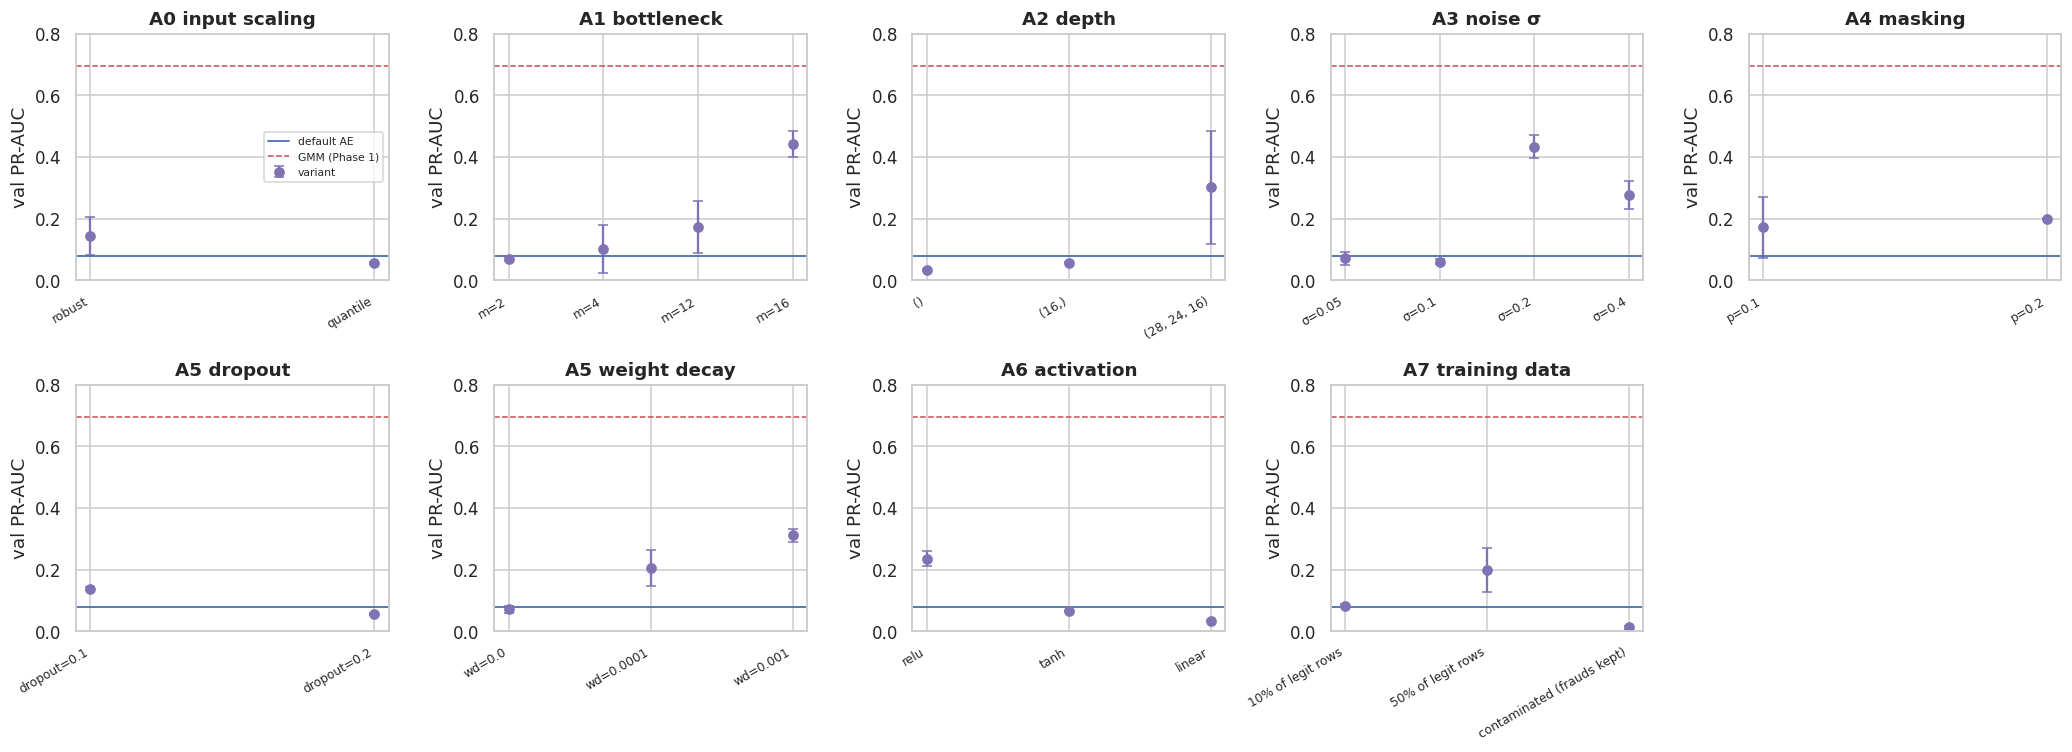

,group,setting,val_ap_mean,val_ap_std,epochs,sec_per_seed
0,default,default AE,0.0781,0.0208,200.0,35.5575
1,A0 input scaling,robust,0.1436,0.0630,200.0,33.2799
2,A0 input scaling,quantile,0.0553,0.0044,200.0,33.2535
3,A1 bottleneck,m=2,0.0683,0.0061,150.5,24.5933
4,A1 bottleneck,m=4,0.1012,0.0771,161.0,26.3581
5,A1 bottleneck,m=12,0.1721,0.0834,181.5,29.7858
6,A1 bottleneck,m=16,0.4422,0.0422,175.0,29.2478
7,A2 depth,(),0.0343,0.0005,45.0,4.8216
8,A2 depth,"(16,)",0.0558,0.0016,168.0,23.0814
9,A2 depth,"(28, 24, 16)",0.3012,0.1838,187.0,37.6544


In [5]:
default_ap = abl.loc[abl.group == "default", "val_ap_mean"].item()
groups = [g for g in dict.fromkeys(abl.group) if g != "default"]
fig, axes = plt.subplots(2, 5, figsize=(19, 7))
for ax, gname in zip(axes.ravel(), groups):
    s = abl[abl.group == gname]
    ax.errorbar(range(len(s)), s.val_ap_mean, yerr=s.val_ap_std, fmt="o", capsize=3, color="#8172B3", label="variant")
    ax.axhline(default_ap, color="#4C72B0", ls="-", lw=1.2, label="default AE")
    ax.axhline(pr_auc(y_val, s_val_gmm), color=C_FRAUD, ls="--", lw=1, label="GMM (Phase 1)")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s.setting, rotation=30, ha="right", fontsize=8)
    ax.set_title(gname); ax.set_ylabel("val PR-AUC"); ax.set_ylim(0, 0.8)
axes[0, 0].legend(fontsize=7)
for ax in axes.ravel()[len(groups):]:
    ax.axis("off")
plt.tight_layout(); savefig("03_ablations"); plt.show()
abl[["group", "setting", "val_ap_mean", "val_ap_std", "epochs", "sec_per_seed"]].round(4)

**What the ablations show** (validation PR-AUC; the default network scores only ≈ 0.08):
* **A1 bottleneck — the single biggest effect.** Small codes (m = 2–8) are poor and m = 16 is by far the best
  (≈ 0.44). The 28 V-features are PCA scores with fairly evenly spread variance, so legitimate behaviour has no
  very-low-dimensional structure. A tight bottleneck cannot rebuild *legitimate* rows well, and their large errors
  drown the fraud signal. With m = 16 legitimate rows are rebuilt accurately while frauds still are not.
* **A6 activation — non-linearity is essential.** The **linear** autoencoder (≈ PCA, Baldi & Hornik 1989) is the
  worst variant (≈ 0.03). Tanh is weak, ReLU and ELU work. The learned non-linear mapping is what makes reconstruction
  error useful at all.
* **A2 depth.** No hidden layer (a single linear map into the code) fails. A deeper encoder helps but is unstable
  across seeds.
* **A3/A4 denoising.** Small Gaussian noise (σ ≤ 0.1) does nothing; **σ = 0.2 is a large improvement** (≈ 0.43);
  σ = 0.4 is too much. Masking noise is clearly weaker than Gaussian noise here.
* **A5 regularisation.** Dropout *hurts*: it makes reconstructions noisier, which is exactly the signal we score.
  Stronger L2 weight decay (1e-3) helps, because it gives a smoother mapping that generalises less to unusual inputs.
* **A0 input scaling.** Unlike the GMM, the autoencoder does *not* like quantile inputs (they clip the extremes that
  make fraud easy to spot). Robust scaling is slightly better than standard scaling on its own.
* **A7 training data.** More legitimate data helps. **Contamination is catastrophic**: leaving the 0.2 % of training
  frauds in the training set collapses the detector, because the network learns to rebuild those extreme points too.
  The legitimate-only protocol of the brief is essential for this model.

## 4. Final models, chosen on validation
Ablation factors can **interact**: a change that helps alone may hurt in combination. So we do not simply stack all
"winning" changes. We build a short list of candidates and compare them all on validation (2 seeds):
* the default network;
* each factor's best setting on its own (already measured in §3);
* the two strongest changes combined;
* all improving changes combined.

The **AE** is the best candidate. The **DAE** is that network plus the better of the two best corruptions (Gaussian
noise or masking), again compared on validation.

In [6]:
def best_in(group):
    s = abl[abl.group == group]
    r = s.loc[s.val_ap_mean.idxmax()]
    return r.setting, r.val_ap_mean, r.val_ap_std, dict(GRID[group])[r.setting]


def evaluate_cfg(kw):
    kw = dict(kw)
    scaler = kw.pop("scaler", "standard")
    _, Xtr_, Xv_, _ = DATA[scaler]
    aps = [pr_auc(y_val, ae_score(train_ae(Xtr_, replace(base, seed=sd, **kw))[0], Xv_)) for sd in ABL_SEEDS]
    return np.mean(aps), np.std(aps)


ARCH = ["A0 input scaling", "A1 bottleneck", "A2 depth", "A5 dropout", "A5 weight decay", "A6 activation"]
improving = []
for gname in ARCH:
    setting, m_, s_, kw = best_in(gname)
    if m_ > default_ap:
        improving.append((m_, s_, f"{gname}: {setting}", kw))
improving.sort(key=lambda t: -t[0])
cands = [dict(candidate="default", kw={}, val_ap_mean=default_ap,
              val_ap_std=abl.loc[abl.group == "default", "val_ap_std"].item(), source="§3")]
cands += [dict(candidate=name, kw=kw, val_ap_mean=m_, val_ap_std=s_, source="§3") for m_, s_, name, kw in improving]
if len(improving) >= 2:
    kw2 = {**improving[0][3], **improving[1][3]}
    m_, s_ = evaluate_cfg(kw2)
    cands.append(dict(candidate="top-2 combined", kw=kw2, val_ap_mean=m_, val_ap_std=s_, source="new"))
if len(improving) >= 3:
    kw_all = {k: v for *_, kw in improving for k, v in kw.items()}
    m_, s_ = evaluate_cfg(kw_all)
    cands.append(dict(candidate="all improvements combined", kw=kw_all, val_ap_mean=m_, val_ap_std=s_, source="new"))
cands = pd.DataFrame(cands)
best_c = cands.loc[cands.val_ap_mean.idxmax()]
ae_kw = dict(best_c.kw)
AE_SCALER = ae_kw.pop("scaler", "standard")
cfg_ae = replace(base, **ae_kw)

# DAE: chosen network + best Gaussian noise or best masking, compared on validation
dae_rows = []
for gname in ["A3 noise σ", "A4 masking"]:
    setting, *_ , kw = best_in(gname)
    m_, s_ = evaluate_cfg({**best_c.kw, **kw})
    dae_rows.append(dict(candidate=f"chosen AE + {setting}", kw=kw, val_ap_mean=m_, val_ap_std=s_, source="new"))
dae_c = pd.DataFrame(dae_rows)
cfg_dae = replace(cfg_ae, **dae_c.loc[dae_c.val_ap_mean.idxmax(), "kw"])
selection = pd.concat([cands, dae_c], ignore_index=True)
print("AE inputs:", AE_SCALER)
print("AE  config:", cfg_ae)
print("DAE config:", cfg_dae)
pre_ae, Xtr, Xv, Xte = inputs(AE_SCALER)
selection[["candidate", "val_ap_mean", "val_ap_std", "source"]].round(4)

AE inputs: standard
AE  config: Cfg(hidden=(24, 16), latent=16, act='elu', dropout=0.0, noise=0.0, mask=0.0, wd=1e-05, lr=0.002, batch=2048, epochs=200, patience=10, seed=0)
DAE config: Cfg(hidden=(24, 16), latent=16, act='elu', dropout=0.0, noise=0.2, mask=0.0, wd=1e-05, lr=0.002, batch=2048, epochs=200, patience=10, seed=0)


,candidate,val_ap_mean,val_ap_std,source
0,default,0.0781,0.0208,§3
1,A1 bottleneck: m=16,0.4422,0.0422,§3
2,A5 weight decay: wd=0.001,0.3106,0.0206,§3
3,"A2 depth: (28, 24, 16)",0.3012,0.1838,§3
4,A6 activation: relu,0.2347,0.0241,§3
5,A0 input scaling: robust,0.1436,0.0630,§3
6,A5 dropout: dropout=0.1,0.1373,0.0049,§3
7,top-2 combined,0.2755,0.1829,new
8,all improvements combined,0.0235,0.0004,new
9,chosen AE + σ=0.2,0.6213,0.0361,new


AE: val 0.512 ± 0.105 | test per seed [0.583, 0.48, 0.644] -> 0.569 ± 0.068
DAE: val 0.622 ± 0.030 | test per seed [0.611, 0.639, 0.635] -> 0.628 ± 0.013


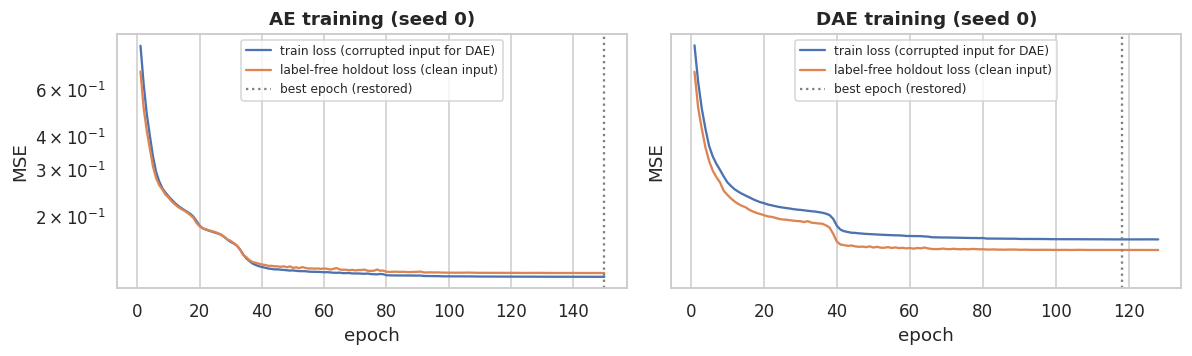

In [7]:
final, hist_seed0 = {}, {}
for name, cfg in [("AE", cfg_ae), ("DAE", cfg_dae)]:
    sv, st, per_seed = [], [], []
    for sd in SEEDS:
        m, h = train_ae(Xtr, replace(cfg, seed=sd))
        a, b = ae_score(m, Xv), ae_score(m, Xte)
        sv.append(a); st.append(b)
        per_seed.append(dict(seed=sd, val_ap=pr_auc(y_val, a), test_ap=pr_auc(y_test, b), epochs=len(h)))
        if sd == SEEDS[0]:
            final[name + "_model"], hist_seed0[name] = m, h
    final[name] = dict(val=np.mean(sv, 0), test=np.mean(st, 0), per_seed=pd.DataFrame(per_seed))
    ps = final[name]["per_seed"]
    print(f"{name}: val {ps.val_ap.mean():.3f} ± {ps.val_ap.std(ddof=0):.3f} | test per seed {ps.test_ap.round(3).tolist()} "
          f"-> {ps.test_ap.mean():.3f} ± {ps.test_ap.std(ddof=0):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (name, h) in zip(axes, hist_seed0.items()):
    ax.plot(h.epoch, h.train_loss, label="train loss (corrupted input for DAE)")
    ax.plot(h.epoch, h.holdout_loss, label="label-free holdout loss (clean input)")
    ax.axvline(h.holdout_loss.idxmin() + 1, color="grey", ls=":", label="best epoch (restored)")
    ax.set(title=f"{name} training (seed 0)", xlabel="epoch", ylabel="MSE", yscale="log"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("03_training_curves"); plt.show()

## 5. Test evaluation: Phase 1 vs Phase 2
Autoencoder scores are averaged over the 3 seeds (a small ensemble). Thresholds come from validation as before.

In [8]:
scores = {
    "GMM (Phase 1)": (s_val_gmm, s_test_gmm),
    "Undercomplete AE": (final["AE"]["val"], final["AE"]["test"]),
    "Denoising AE": (final["DAE"]["val"], final["DAE"]["test"]),
}
reports = [evaluate(n, y_val, sv, y_test, st) for n, (sv, st) in scores.items()]
table = summary_table(reports)
table.round(3)

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
GMM (Phase 1),0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
Undercomplete AE,0.584,0.618,"[0.502, 0.743]",0.938,0.703,0.000,0.770,0.003,0.770,0.006,0.72,0.52,0.285,0.114
Denoising AE,0.680,0.661,"[0.547, 0.784]",0.940,0.703,0.001,0.784,0.003,0.797,0.006,0.84,0.55,0.285,0.118


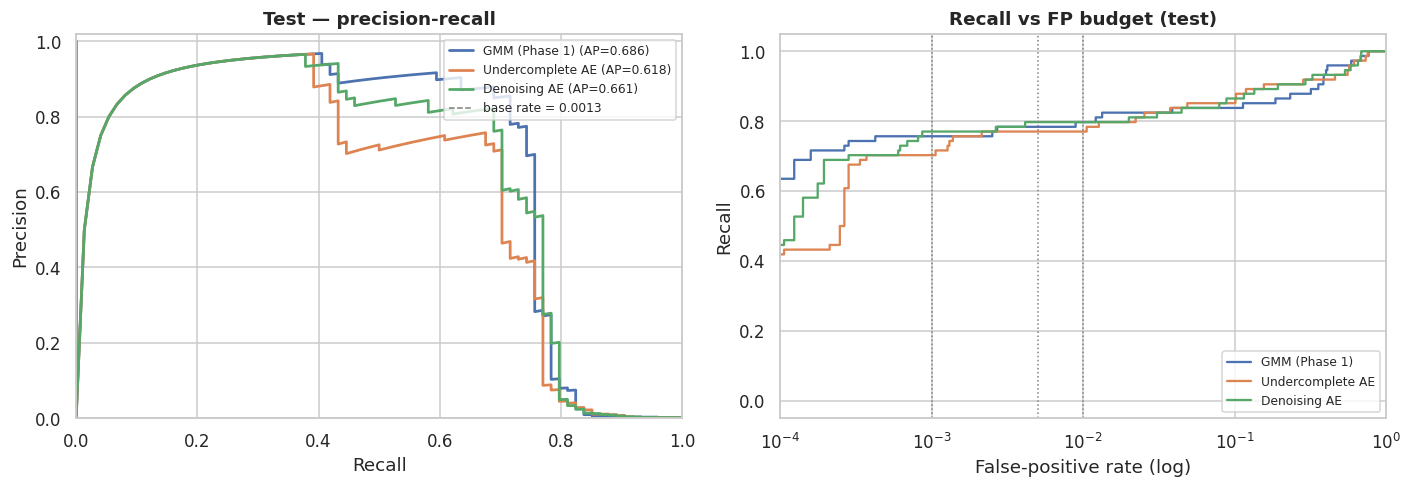

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_pr_curves(y_test, {k: v[1] for k, v in scores.items()}, "Test — precision-recall", ax=axes[0])
from sklearn.metrics import roc_curve
for n_, (_, st) in scores.items():
    fpr, tpr, _ = roc_curve(y_test, st)
    axes[1].plot(fpr, tpr, label=n_)
for f in FPR_BUDGETS:
    axes[1].axvline(f, color="grey", ls=":", lw=1)
axes[1].set(xscale="log", xlim=(1e-4, 1), xlabel="False-positive rate (log)", ylabel="Recall", title="Recall vs FP budget (test)")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("03_pr_curves_gmm_vs_ae"); plt.show()

### Is the difference real? Paired bootstrap on the test set
Resample the test set 1,000 times (stratified) and compute PR-AUC(A) − PR-AUC(B) on each resample. If the 95 %
interval excludes 0, the difference is unlikely to be luck.

In [10]:
sig = {
    "Undercomplete AE − GMM": paired_bootstrap(y_test, scores["Undercomplete AE"][1], s_test_gmm),
    "Denoising AE − GMM": paired_bootstrap(y_test, scores["Denoising AE"][1], s_test_gmm),
    "Denoising AE − Undercomplete AE": paired_bootstrap(y_test, scores["Denoising AE"][1], scores["Undercomplete AE"][1]),
}
pd.DataFrame(sig).T

,diff,ci,p_not_better
Undercomplete AE − GMM,-0.068366,"[-0.10690678722437726, -0.031996022393392935]",1.0
Denoising AE − GMM,-0.024924,"[-0.05521727321274572, 0.0013057211642753057]",0.964
Denoising AE − Undercomplete AE,0.043442,"[0.017524082772096657, 0.07521501631545675]",0.0


**Model selection.** Stacking every individually-helpful change produced a *bad* network (validation ≈ 0.02),
because the factors interact (for example a wide code + dropout + a deeper stack). The candidate comparison
therefore selected the **single best change, a 16-unit bottleneck** (standard inputs, 24–16 hidden layers, ELU). The
**denoising** version adds Gaussian input noise σ = 0.2, which is clearly better on validation.

**Test results.**
* **Denoising AE: PR-AUC 0.661** (95 % CI 0.55–0.78). Statistically on par with the Phase-1 GMM (0.686): paired
  difference −0.025, CI [−0.055, +0.001]. It is also **stable**: 0.61–0.64 across seeds.
* **Undercomplete AE: 0.618.** Significantly below the GMM (−0.068, CI [−0.107, −0.032]) and unstable across seeds
  (0.48–0.64).
* **Denoising beats plain reconstruction:** +0.043, CI [+0.018, +0.075]. Denoising acts as a strong regulariser (Vincent
  et al., 2008). It improves the ranking *and* removes most of the seed-to-seed variance.
* **At strict budgets the GMM is still better.** At the 0.1 % budget both autoencoders catch 70 % of frauds against 76 %
  for the GMM. The GMM's top-50 queue is 90 % fraud against 84 % for the DAE.

## 6. Threshold analysis and false-positive trade-offs

In [11]:
rows = []
for r in reports:
    for f, b in r["budgets"].items():
        rows.append({"model": r["model"], "policy": f"FP budget {float(f):.1%}", "alerts": b["alerts"], "frauds caught": b["tp"],
                     "recall": b["recall"], "precision": b["precision"], "realised FPR": b["fpr"]})
    for k, c in r["capacity"].items():
        rows.append({"model": r["model"], "policy": f"top-{k} queue", "alerts": int(k), "frauds caught": c["tp"],
                     "recall": c["recall"], "precision": c["precision"]})
ops = pd.DataFrame(rows)
ops.round(3)

,model,policy,alerts,frauds caught,recall,precision,realised FPR
0,GMM (Phase 1),FP budget 0.1%,94,56,0.757,0.596,0.001
1,GMM (Phase 1),FP budget 0.5%,221,58,0.784,0.262,0.003
2,GMM (Phase 1),FP budget 1.0%,399,58,0.784,0.145,0.006
3,GMM (Phase 1),top-50 queue,50,45,0.608,0.900,NaN
4,GMM (Phase 1),top-100 queue,100,56,0.757,0.560,NaN
5,GMM (Phase 1),top-200 queue,200,57,0.770,0.285,NaN
6,GMM (Phase 1),top-500 queue,500,58,0.784,0.116,NaN
7,Undercomplete AE,FP budget 0.1%,79,52,0.703,0.658,0.000
8,Undercomplete AE,FP budget 0.5%,234,57,0.770,0.244,0.003
9,Undercomplete AE,FP budget 1.0%,405,57,0.770,0.141,0.006


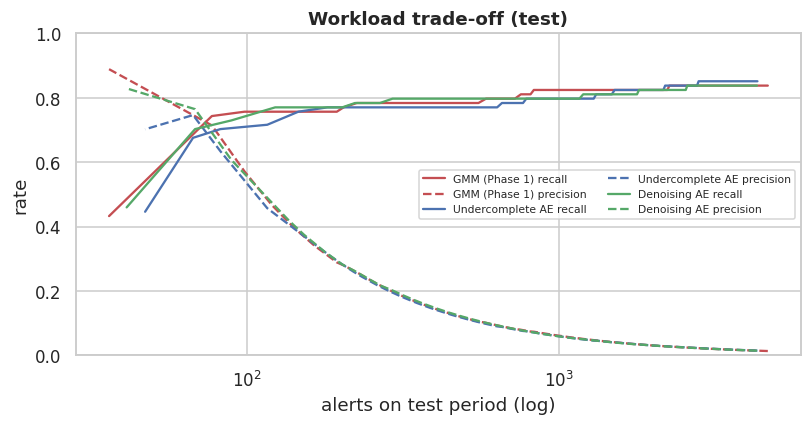

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (n_, (sv, st)), c in zip(scores.items(), [C_FRAUD, "#4C72B0", "#55A868"]):
    thr = np.quantile(sv, np.linspace(0.90, 0.9995, 150))
    cur = pd.DataFrame([confusion_at(y_test, st, t) for t in thr])
    ax.plot(cur.alerts, cur.recall, color=c, label=f"{n_} recall")
    ax.plot(cur.alerts, cur.precision, color=c, ls="--", label=f"{n_} precision")
ax.set(xscale="log", xlabel="alerts on test period (log)", ylabel="rate", ylim=(0, 1), title="Workload trade-off (test)")
ax.legend(fontsize=7, ncol=2); savefig("03_threshold_tradeoff"); plt.show()

## 7. Diagnosis — why does reconstruction error trail the Gaussian density?
Three checks, each tied to theory:
1. **Redundancy.** If the AE error mostly re-measures what the GMM already sees, the two scores are strongly
   rank-correlated, especially on fraud.
2. **Direction weighting.** Mahalanobis/GMM distance divides each direction by its variance, $\sum_j u_j^2/\lambda_j$.
   Directions in which legitimate data barely varies (tiny $\lambda_j$) get huge weight, and that is where fraud
   breaks the normal pattern. Plain MSE weights every residual direction equally. We re-score the *same* AE residuals
   with a Gaussian fitted to legitimate residuals (a Mahalanobis residual score) to see how much this matters.
3. **Over-generalisation.** A network that reconstructs legitimate data well also partly reconstructs fraud. We
   measure what fraction of each fraud's deviation from the legitimate mean the AE manages to reproduce.

In [13]:
from scipy.stats import spearmanr
m_ae = final["AE_model"]
xh_te, z_te = recon(m_ae, Xte)
res_te = Xte - xh_te
hold_rows = Xtr[m_ae.hold_idx]
res_hold = hold_rows - recon(m_ae, hold_rows)[0]
g_res = GaussianMixture(1, covariance_type="full", reg_covar=1e-4).fit(res_hold)
s_res_maha = -g_res.score_samples(res_te)
dev = Xte - Xtr.mean(0)
explained = 1 - (res_te ** 2).sum(1) / ((dev ** 2).sum(1) + 1e-9)
diag = pd.DataFrame({
    "Spearman(AE error, GMM score) — legit": [spearmanr(final["AE"]["test"][y_test == 0], s_test_gmm[y_test == 0]).statistic],
    "Spearman(AE error, GMM score) — fraud": [spearmanr(final["AE"]["test"][y_test == 1], s_test_gmm[y_test == 1]).statistic],
    "test AP: AE, MSE score": [pr_auc(y_test, ae_score(m_ae, Xte))],
    "test AP: same AE, Mahalanobis residual score": [pr_auc(y_test, s_res_maha)],
    "median share of deviation reconstructed — legit": [np.median(explained[y_test == 0])],
    "median share of deviation reconstructed — fraud": [np.median(explained[y_test == 1])],
}).T.rename(columns={0: "value"})
diag.round(3)

,value
"Spearman(AE error, GMM score) — legit",0.429
"Spearman(AE error, GMM score) — fraud",0.941
"test AP: AE, MSE score",0.583
"test AP: same AE, Mahalanobis residual score",0.171
median share of deviation reconstructed — legit,0.736
median share of deviation reconstructed — fraud,0.317


**What the diagnosis shows.**
1. **On frauds, the two detectors agree** (Spearman ρ ≈ 0.94): the AE and the GMM find the *same* frauds suspicious.
   **On legitimate rows they disagree** (ρ ≈ 0.43): they raise *different* false alarms. This is the opening a hybrid
   can try to exploit (Notebook 04).
2. **Direction weighting — the simple theoretical fix does not work.** Re-scoring the same AE residuals with a Gaussian
   fitted to legitimate residuals (a Mahalanobis residual score) *drops* test PR-AUC from ≈ 0.58 to ≈ 0.17. The
   residuals of legitimate rows are themselves heavy-tailed, so a single Gaussian on them is a poor model and amplifies
   noise. This is the same lesson as Phase 1: Gaussian assumptions break on raw heavy-tailed data.
3. **Over-generalisation is real but limited.** The AE reproduces ≈ 74 % of a typical legitimate row's deviation from the
   mean, but only ≈ 32 % of a typical fraud's. It does partly rebuild fraud (which caps its recall), yet the gap is
   large enough to rank most frauds high.

## 8. Why does the AE flag a transaction? Per-feature reconstruction error
Reconstruction error decomposes over features: $e(\mathbf{x})=\frac1d\sum_j(x_j-\hat x_j)^2$. Averaging the per-feature
terms over frauds vs legitimate rows shows *which* features the model fails to rebuild for fraud. This gives an
analyst a reason for each alert.

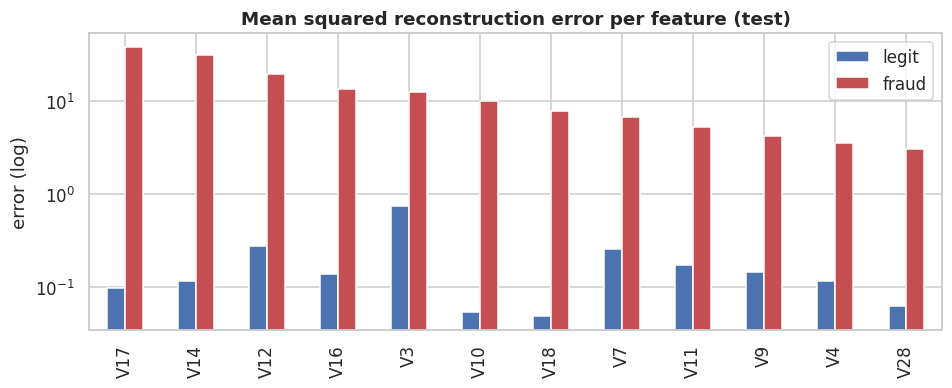

,legit,fraud,ratio
V17,0.097,38.015999,393.690002
V14,0.115,30.662001,266.963013
V12,0.273,19.211000,70.481003
V16,0.138,13.429000,97.200996
V3,0.733,12.477000,17.028000
V10,0.054,10.048000,185.201996
V18,0.048,7.842000,162.621994
V7,0.252,6.737000,26.757000
V11,0.173,5.226000,30.285000
V9,0.145,4.158000,28.624001


In [14]:
per_feat = res_te ** 2
contrib = pd.DataFrame({"legit": per_feat[y_test == 0].mean(0), "fraud": per_feat[y_test == 1].mean(0)}, index=pre_ae.cols)
contrib["ratio"] = contrib.fraud / contrib.legit
top = contrib.sort_values("fraud", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 3.5))
top[["legit", "fraud"]].plot.bar(ax=ax, color=[C_LEGIT, C_FRAUD], logy=True)
ax.set(title="Mean squared reconstruction error per feature (test)", ylabel="error (log)")
savefig("03_feature_errors"); plt.show()
top.round(3)

## 9. Score distribution and latent space

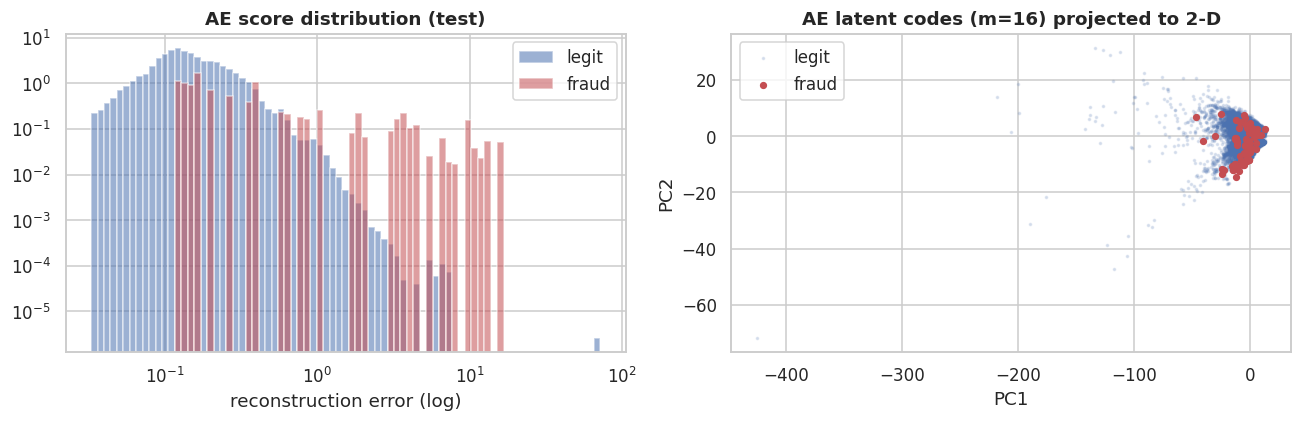

In [15]:
z2 = PCA(2, random_state=SEED).fit_transform(z_te)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
st = final["AE"]["test"]
bins = np.logspace(np.log10(np.quantile(st, .001)), np.log10(st.max()), 80)
axes[0].hist(st[y_test == 0], bins=bins, density=True, alpha=.55, color=C_LEGIT, label="legit")
axes[0].hist(st[y_test == 1], bins=bins, density=True, alpha=.55, color=C_FRAUD, label="fraud")
axes[0].set(xscale="log", yscale="log", xlabel="reconstruction error (log)", title="AE score distribution (test)"); axes[0].legend()
axes[1].scatter(z2[y_test == 0, 0], z2[y_test == 0, 1], s=2, alpha=.15, color=C_LEGIT, label="legit")
axes[1].scatter(z2[y_test == 1, 0], z2[y_test == 1, 1], s=14, color=C_FRAUD, label="fraud")
axes[1].set(title=f"AE latent codes (m={cfg_ae.latent}) projected to 2-D", xlabel="PC1", ylabel="PC2"); axes[1].legend()
plt.tight_layout(); savefig("03_scores_and_latent"); plt.show()

## 10. Phase-2 (autoencoder) conclusions
1. **A well-designed autoencoder works, but design matters enormously.** The default network scores ≈ 0.08 on
   validation; the selected denoising AE scores ≈ 0.66 on test. The bottleneck size, non-linearity and Gaussian input
   noise make the difference. Stacking every helpful change without re-validating breaks it.
2. **The denoising AE matches the GMM within statistical noise** (0.661 vs 0.686), and is the most stable deep model.
   The plain undercomplete AE is significantly worse and seed-sensitive.
3. **Neither autoencoder beats the GMM.** At strict false-positive budgets the GMM is still ahead. On fraud they rank
   transactions almost identically; on legitimate rows they make different mistakes.
4. **The legitimate-only protocol is essential.** Even 0.2 % fraud contamination in training destroys the detector.

**Next (Notebook 04).** Because the two models make *different* false alarms, we test whether a hybrid that combines
the Gaussian density with the autoencoder can beat both.

In [16]:
phase2 = dict(phase1_cfg=P1, ae_scaler=AE_SCALER, cfg_ae=asdict(cfg_ae), cfg_dae=asdict(cfg_dae), device=DEVICE,
              ablations=abl.to_dict("records"),
              selection=selection.assign(kw=selection.kw.astype(str)).to_dict("records"), reports=reports, significance=sig,
              per_seed={k: final[k]["per_seed"].to_dict("records") for k in ["AE", "DAE"]},
              diagnosis=diag["value"].to_dict(), feature_errors=top.reset_index().to_dict("records"))
save_json(phase2, "03_phase2_ae_results.json")
display(table.round(3))
finish_colab("outputs_03_phase2_ae")

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
GMM (Phase 1),0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
Undercomplete AE,0.584,0.618,"[0.502, 0.743]",0.938,0.703,0.000,0.770,0.003,0.770,0.006,0.72,0.52,0.285,0.114
Denoising AE,0.680,0.661,"[0.547, 0.784]",0.940,0.703,0.001,0.784,0.003,0.797,0.006,0.84,0.55,0.285,0.118


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>